# Изучение параметров SIFT

In [2]:
from pathlib import Path
from itertools import combinations

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
ROOT = Path.cwd()

## 1. Загрузка
Уменьшаем только большие снимки до 1400 px по длинной стороне. Пропорции сохраняются.
OpenCV читает цвет как BGR; для вывода через Matplotlib преобразуем его в RGB.

In [3]:
paths = sorted((ROOT / "PLANKTON").glob("*.jpg"))
images = []
for path in paths:
    image = cv2.imread(str(path))
    height, width = image.shape[:2]
    scale = min(1.0, 1400 / max(height, width))
    image = cv2.resize(image, (round(width * scale), round(height * scale)),
                       interpolation=cv2.INTER_AREA)
    images.append(image)

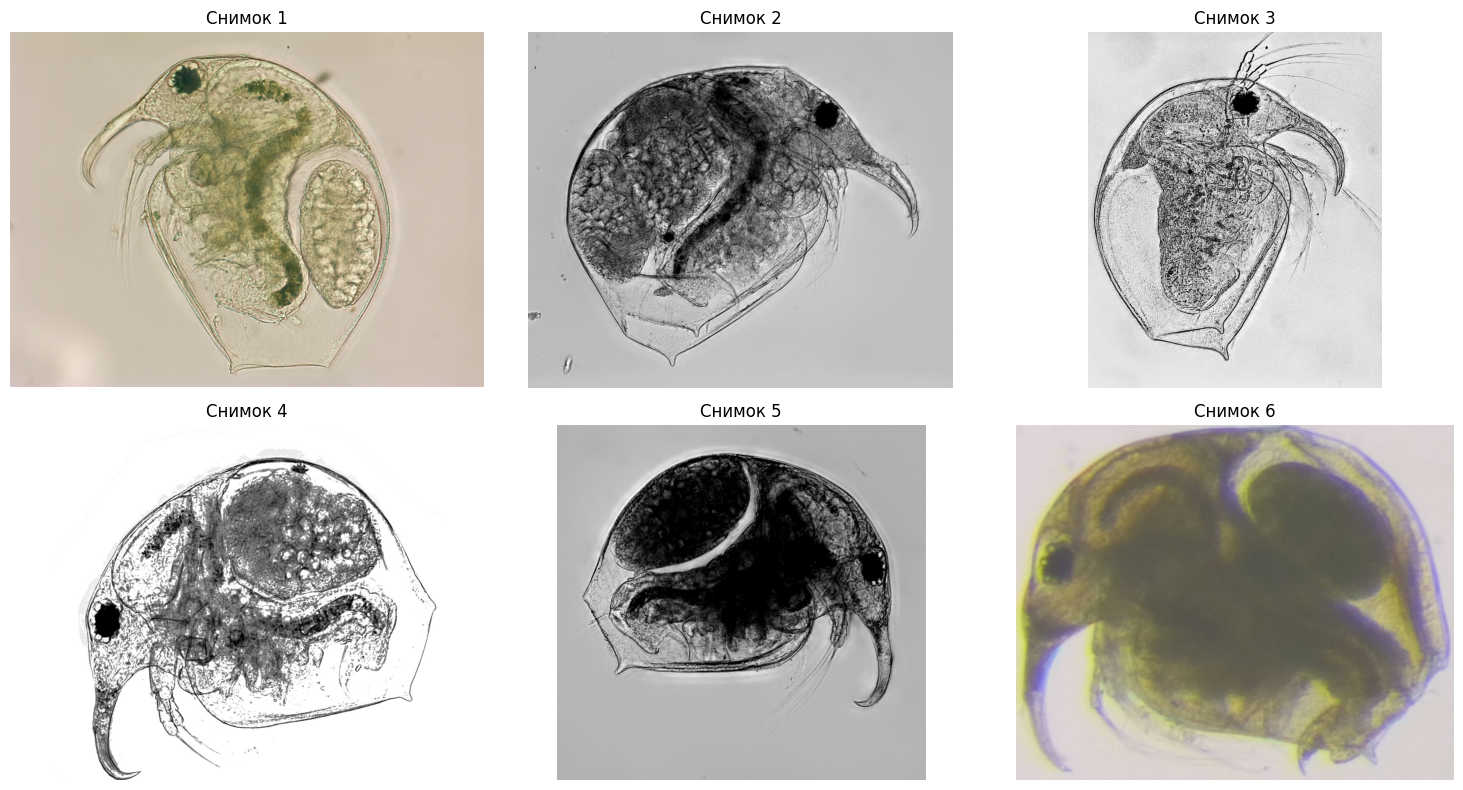

In [4]:
def show_grid(pictures, titles, columns=3):
    rows = (len(pictures) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4 * rows),
                             squeeze=False)
    for ax, picture, title in zip(axes.flat, pictures, titles):
        if picture.ndim == 2:
            ax.imshow(picture, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(picture, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_grid(images, [f"Снимок {i + 1}" for i in range(len(images))])

## 2. Базовая предобработка
**Gray** оставляет яркость. **GaussianBlur 3×3** слегка подавляет мелкий шум.
**CLAHE** усиливает контраст в локальных областях; `clipLimit=2.0` ограничивает
усиление, а `tileGridSize=(8, 8)` задаёт сетку областей.
Маска, отражение и ручная разметка здесь не используются.

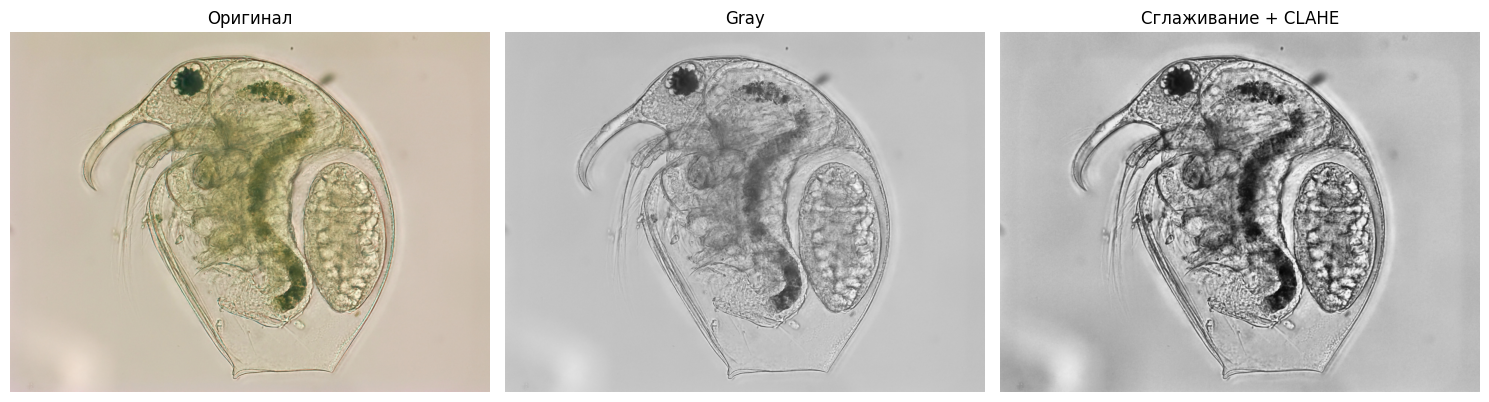

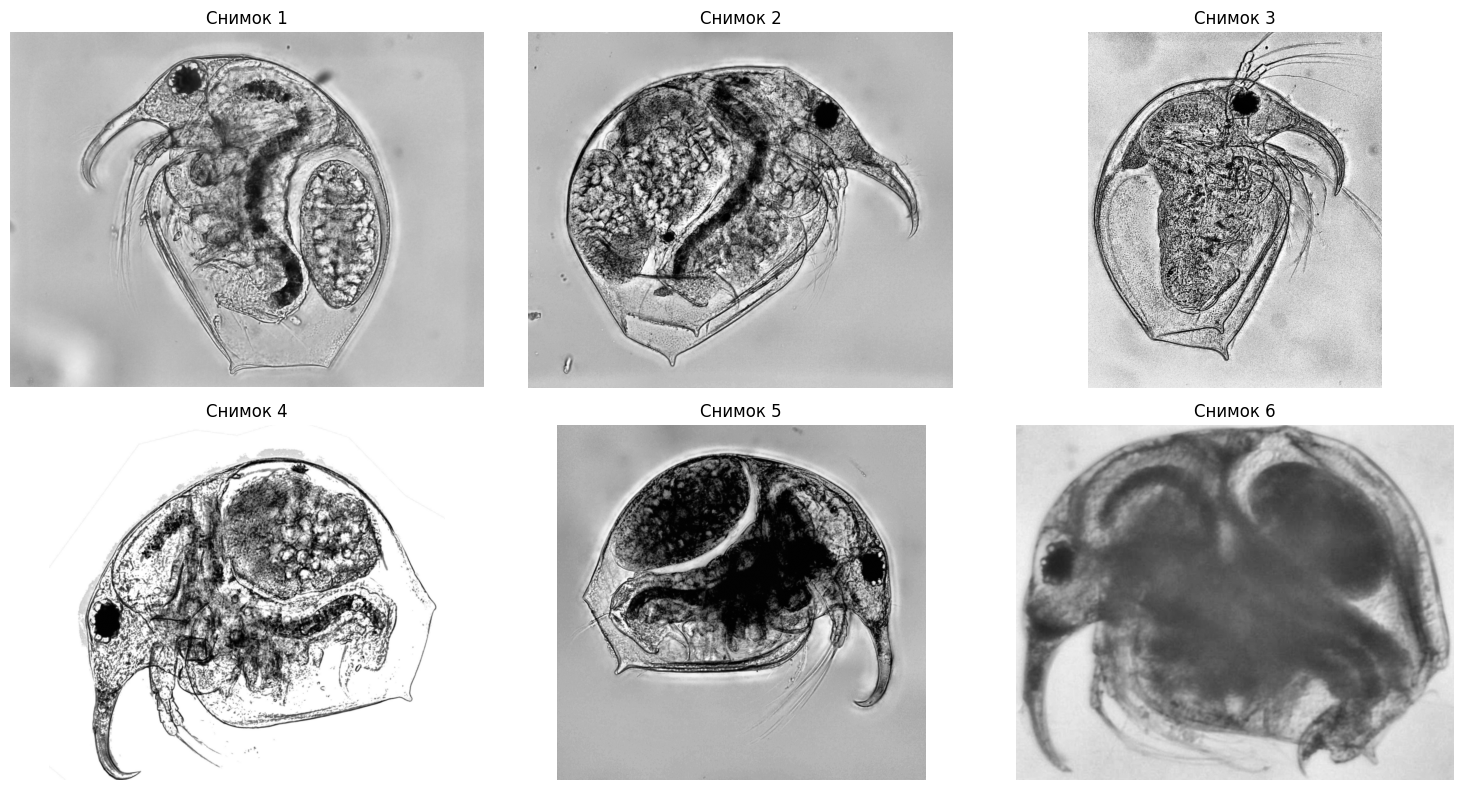

In [5]:
gray_images = []
processed = []
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

for image in images:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0)
    normalized = clahe.apply(blurred)
    gray_images.append(gray)
    processed.append(normalized)

show_grid([images[0], gray_images[0], processed[0]],
          ["Оригинал", "Gray", "Сглаживание + CLAHE"])
show_grid(processed, [f"Снимок {i + 1}" for i in range(len(images))])

## 3. Ключевые точки и дескрипторы SIFT
- `nfeatures` - 3000 - Лимит сохраняемых сильных точек; при равных откликах возможен небольшой избыток 
- `nOctaveLayers` - 3 - Число слоёв масштаба в октаве 
- `contrastThreshold` - 0.04 - Отбор по контрасту; снижение пропускает больше слабых деталей 
- `edgeThreshold` - 10 - Отбор вытянутых деталей; увеличение ослабляет фильтрацию 
- `sigma` - 1.6 - Начальное сглаживание SIFT 

`detectAndCompute` возвращает точки и матрицу дескрипторов — по 128 чисел на точку.

In [6]:
sift_params = dict(nfeatures=3000, nOctaveLayers=3, contrastThreshold=0.04,
                   edgeThreshold=10, sigma=1.6)
sift = cv2.SIFT_create(**sift_params)
keypoints, descriptors = [], []
for image in processed:
    points, vectors = sift.detectAndCompute(image, None)
    keypoints.append(points)
    descriptors.append(vectors)

for i, (points, vectors) in enumerate(zip(keypoints, descriptors), start=1):
    print(f"Снимок {i}: {len(points)} точек; дескрипторы: "
          f"{None if vectors is None else vectors.shape}")

Снимок 1: 3002 точек; дескрипторы: (3002, 128)
Снимок 2: 3001 точек; дескрипторы: (3001, 128)
Снимок 3: 3000 точек; дескрипторы: (3000, 128)
Снимок 4: 3001 точек; дескрипторы: (3001, 128)
Снимок 5: 3001 точек; дескрипторы: (3001, 128)
Снимок 6: 492 точек; дескрипторы: (492, 128)


In [7]:
matcher = cv2.BFMatcher(cv2.NORM_L2)

def ratio_matches(source, target):
    if source is None or target is None or len(target) < 2:
        return []
    matches = []
    for neighbors in matcher.knnMatch(source, target, k=2):
        if len(neighbors) == 2:
            best, second = neighbors
            if best.distance < 0.8 * second.distance:
                matches.append(best)
    return matches

In [8]:
pair_matches, pair_stats = {}, []
for i, j in combinations(range(len(images)), 2):
    forward = ratio_matches(descriptors[i], descriptors[j])
    backward = ratio_matches(descriptors[j], descriptors[i])
    reverse_pairs = {(m.trainIdx, m.queryIdx) for m in backward}
    mutual = [m for m in forward if (m.queryIdx, m.trainIdx) in reverse_pairs]
    pair_matches[(i, j)] = sorted(mutual, key=lambda m: m.distance)
    print(f"pair : {i + 1, j + 1} | ", f"after_ratio: {len(forward)} | ",
                       f"mutual: {len(mutual)}")

pair : (1, 2) |  after_ratio: 37 |  mutual: 9
pair : (1, 3) |  after_ratio: 36 |  mutual: 4
pair : (1, 4) |  after_ratio: 50 |  mutual: 17
pair : (1, 5) |  after_ratio: 41 |  mutual: 14
pair : (1, 6) |  after_ratio: 57 |  mutual: 6
pair : (2, 3) |  after_ratio: 40 |  mutual: 10
pair : (2, 4) |  after_ratio: 33 |  mutual: 9
pair : (2, 5) |  after_ratio: 33 |  mutual: 8
pair : (2, 6) |  after_ratio: 64 |  mutual: 5
pair : (3, 4) |  after_ratio: 23 |  mutual: 3
pair : (3, 5) |  after_ratio: 14 |  mutual: 3
pair : (3, 6) |  after_ratio: 39 |  mutual: 1
pair : (4, 5) |  after_ratio: 40 |  mutual: 10
pair : (4, 6) |  after_ratio: 60 |  mutual: 3
pair : (5, 6) |  after_ratio: 67 |  mutual: 8


In [9]:
def draw_pair(i, j):
    colors = [(0, 255, 255), (255, 0, 255), (255, 255, 0),
              (0, 255, 0), (0, 140, 255), (255, 100, 100)]
    # Пустой список совпадений: OpenCV только размещает снимки рядом.
    view = cv2.drawMatches(images[i], [], images[j], [], [], None)
    points = []
    for number, match in enumerate(pair_matches[(i, j)][:30], 1):
        x1, y1 = keypoints[i][match.queryIdx].pt
        x2, y2 = keypoints[j][match.trainIdx].pt
        a = (round(x1), round(y1))
        b = (round(x2) + images[i].shape[1], round(y2))
        color = colors[(number - 1) % len(colors)]
        cv2.line(view, a, b, (0, 0, 0), 7)
        cv2.line(view, a, b, color, 3)
        points.extend([(a, number, color), (b, number, color)])
    # Подписи рисуем последними, поверх линий.
    for (x, y), number, color in points:
        cv2.circle(view, (x, y), 11, (0, 0, 0), -1)
        cv2.circle(view, (x, y), 8, color, -1)
        label_x = min(x + 15, view.shape[1] - 45)
        label_y = max(y - 15, 30)
        cv2.rectangle(view, (label_x - 3, label_y - 25),
                      (label_x + 40, label_y + 6), (0, 0, 0), -1)
        cv2.putText(view, str(number), (label_x, label_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.85, color, 2)
    return view

## Эксперименты: Изучение параметров SIFT
Меняем один параметр за раз относительно базовых настроек. Предобработка,
ratio test 0.8 и взаимная проверка остаются одинаковыми.
Сравниваем количество точек, попарных кандидатов и общих согласованных треков.
Кандидаты могут быть ошибочными — число линий не является оценкой точности.

In [10]:
# Сохраняем базовый результат, чтобы не вычислять его повторно.
results = {"SIFT": {"points": keypoints, "descriptors": descriptors,
                    "pairs": pair_matches, "tracks": []}}
base_sift = sift_params.copy()
sift_variants = {
    "Базовый": {},
    "Больше точек": {"nfeatures": 6000},
    "Слабее порог контраста": {"contrastThreshold": 0.02},
    "Сильнее порог контраста": {"contrastThreshold": 0.08},
    "Меньше фильтрации краёв": {"edgeThreshold": 20},
    "Меньше сглаживания": {"sigma": 1.2},
    "Больше слоёв масштаба": {"nOctaveLayers": 4},
}
sift_experiments = {}

`nfeatures` ограничивает число точек;

Понижение `contrastThreshold` пропускает слабые детали; 

повышение `edgeThreshold` ослабляет отбор вытянутых деталей;

`sigma` задаёт начальное сглаживание;

`nOctaveLayers` меняет дискретизацию масштаба и эффективный порог контраста в SIFT, поэтому это не изолированное изменение только масштаба.

In [11]:
matcher = cv2.BFMatcher(cv2.NORM_L2)

for label, changes in sift_variants.items():
    params = {**base_sift, **changes}
    if label == "Базовый":
        data = results["SIFT"]
    else:
        detector = cv2.SIFT_create(**params)
        points, descriptors = [], []
        for image in processed:
            p, d = detector.detectAndCompute(image, None)
            points.append(p)
            descriptors.append(d)
        pairs = {}
        for i, j in combinations(range(len(images)), 2):
            forward = ratio_matches(descriptors[i], descriptors[j])
            backward = ratio_matches(descriptors[j], descriptors[i])
            reverse = {(m.trainIdx, m.queryIdx) for m in backward}
            mutual = [m for m in forward if (m.queryIdx, m.trainIdx) in reverse]
            pairs[(i, j)] = sorted(mutual, key=lambda m: m.distance)
        data = {"points": points, "pairs": pairs}
    sift_experiments[label] = {"parameters": params, **data}
    print(label, "— кандидатов:", sum(len(m) for m in data["pairs"].values()), flush=True)

Базовый — кандидатов: 110
Больше точек — кандидатов: 181
Слабее порог контраста — кандидатов: 123
Сильнее порог контраста — кандидатов: 94
Меньше фильтрации краёв — кандидатов: 108
Меньше сглаживания — кандидатов: 121
Больше слоёв масштаба — кандидатов: 98


### Сводка параметров

In [15]:
rows = ["| Вариант | Точек всего | Попарных кандидатов |", "|---|---:|---:|"]
for label, data in sift_experiments.items():
    points_total = sum(len(p) for p in data["points"])
    matches_total = sum(len(m) for m in data["pairs"].values())
    rows.append(f"| {label} | {points_total} | {matches_total} |")
display(Markdown("\n".join(rows)))

| Вариант | Точек всего | Попарных кандидатов |
|---|---:|---:|
| Базовый | 15497 | 110 |
| Больше точек | 30492 | 181 |
| Слабее порог контраста | 16325 | 123 |
| Сильнее порог контраста | 15087 | 94 |
| Меньше фильтрации краёв | 15527 | 108 |
| Меньше сглаживания | 15460 | 121 |
| Больше слоёв масштаба | 15486 | 98 |

### Визуальное сравнение на паре 1–4

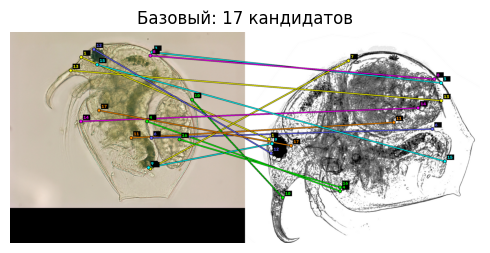

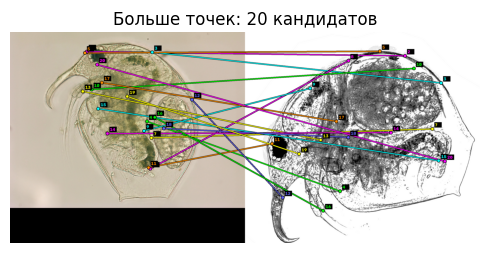

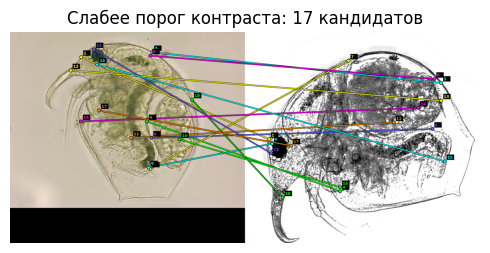

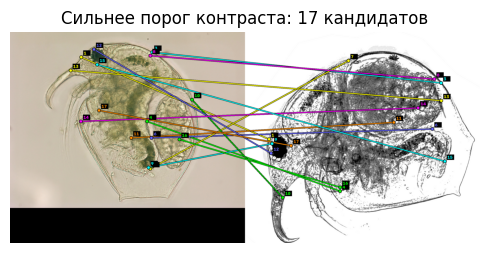

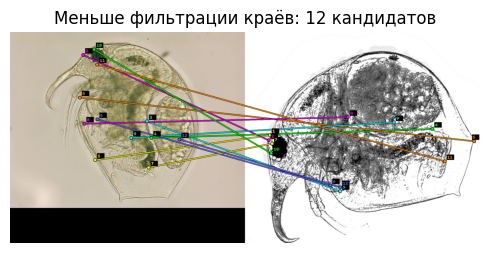

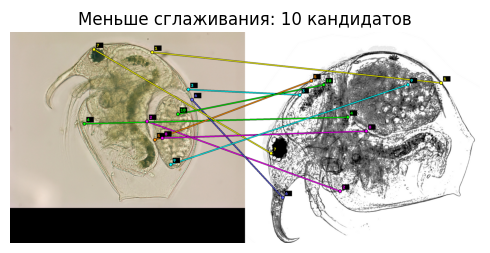

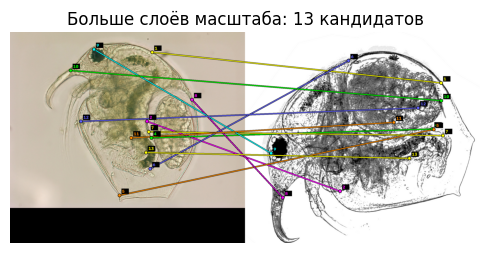

In [14]:
for label, data in sift_experiments.items():
    keypoints = data["points"]
    pair_matches = data["pairs"]
    view = draw_pair(0, 3)
    show_grid([view], [f"{label}: {len(pair_matches[(0, 3)])} кандидатов"], columns=1)
# Возвращаем данные базового SIFT для последующего использования draw_pair.
keypoints = results["SIFT"]["points"]
pair_matches = results["SIFT"]["pairs"]

### Вывод по настройкам
Изменение параметров влияет на число точек
и прошедших отбор кандидатов. Увеличение числа кандидатов не доказывает улучшение
качества; на изображениях остаются ошибочные связи. Общие треки проверены отдельно.
Без эталонной разметки ранжировать настройки по точности нельзя.